In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import pickle
import seaborn as sns

In [42]:
df=pd.read_csv(r"fake_bills.csv",sep=';')
df

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54
...,...,...,...,...,...,...,...
1495,False,171.75,104.38,104.17,4.42,3.09,111.28
1496,False,172.19,104.63,104.44,5.27,3.37,110.97
1497,False,171.80,104.01,104.12,5.51,3.36,111.95
1498,False,172.06,104.28,104.06,5.17,3.46,112.25


Data Cleaning

In [32]:
# =====================================================
# PART 1: DATA CLEANING
# =====================================================
df = pd.read_csv("fake_bills.csv", sep=";")   # dataset uses ';' as separator

print("Shape before cleaning:", df.shape)
print("Missing values:\n", df.isnull().sum())

df.columns = df.columns.str.strip().str.lower()
df = df.drop_duplicates()
df = df.dropna(subset=["is_genuine"])

feature_cols = [c for c in df.columns if c != "is_genuine"]

# Fill missing values (margin_low has some) with the median
df[feature_cols] = df[feature_cols].fillna(df[feature_cols].median())

df["is_genuine"] = df["is_genuine"].astype(int)   # True/False -> 1/0

# Cap extreme values using the IQR rule (set to False to skip)
CAP_OUTLIERS = True
if CAP_OUTLIERS:
    for col in feature_cols:
        q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        iqr = q3 - q1
        df[col] = df[col].clip(lower=q1 - 1.5 * iqr, upper=q3 + 1.5 * iqr)

print("\nShape after cleaning:", df.shape)
print("Number of features:", len(feature_cols), feature_cols)
print("Class balance:\n", df["is_genuine"].value_counts())

Shape before cleaning: (1500, 7)
Missing values:
 is_genuine       0
diagonal         0
height_left      0
height_right     0
margin_low      37
margin_up        0
length           0
dtype: int64

Shape after cleaning: (1500, 7)
Number of features: 6 ['diagonal', 'height_left', 'height_right', 'margin_low', 'margin_up', 'length']
Class balance:
 is_genuine
1    1000
0     500
Name: count, dtype: int64


Training

In [33]:
X = df.drop("is_genuine", axis=1)
y = df["is_genuine"]

# 80% train, 20% test (stratify keeps class ratio equal in both)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42)),
])

model.fit(X_train, y_train)

print("\nTraining accuracy:", round(model.score(X_train, y_train), 4))

with open("logreg_model.pkl", "wb") as f:
    pickle.dump(model, f)


Training accuracy: 0.9925


Testing

In [34]:
# =====================================================
# PART 3: TESTING
# =====================================================
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]    # probability of being genuine

results = X_test.copy()
results["actual"] = y_test.values
results["predicted"] = y_pred
results["probability_genuine"] = y_prob.round(4)

print("\nSample predictions:")
print(results.head(10))
results.to_csv("predictions.csv", index=False)


Sample predictions:
      diagonal  height_left  height_right  margin_low  margin_up  length  \
803     171.87       103.27        104.50        3.85       3.03  113.19   
1306    172.13       103.99        104.06        5.80       3.28  111.30   
1263    171.59       104.05        104.40        5.05       3.45  111.14   
38      172.00       103.76        104.27        4.42       3.29  112.67   
257     172.19       104.03        104.25        4.17       2.81  112.94   
395     171.82       104.33        103.83        3.92       2.73  112.99   
834     172.07       103.61        104.34        4.34       2.85  113.03   
606     171.52       104.52        103.96        3.43       3.01  113.44   
397     172.15       104.18        103.53        3.92       3.30  113.42   
11      171.84       104.59        104.00        3.88       3.27  113.08   

      actual  predicted  probability_genuine  
803        1          1               0.9990  
1306       0          0               0.0000  
1

Evaluation

In [36]:
#Evaluation
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, ConfusionMatrixDisplay
)
# Load predictions made in File 3
results = pd.read_csv("predictions.csv")

y_true = results["actual"]
y_pred = results["predicted"]
y_prob = results["probability_genuine"]
# ---------- Main metrics ----------
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("=" * 40)
print("MODEL EVALUATION (Logistic Regression)")
print("=" * 40)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {auc:.4f}")

# ---------- Confusion matrix breakdown ----------
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)

print("\nConfusion Matrix (rows = actual, cols = predicted):")
print(cm)
print(f"\nTrue Negatives  (fake correctly found)    : {tn}")
print(f"False Positives (fake called genuine)     : {fp}")
print(f"False Negatives (genuine called fake)     : {fn}")
print(f"True Positives  (genuine correctly found) : {tp}")
print(f"Specificity (fake detection rate)         : {specificity:.4f}")

# ---------- Full report ----------
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=["Fake", "Genuine"]))
# ---------- Chart 1: Confusion matrix ----------
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Fake", "Genuine"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.close()

# ---------- Chart 2: ROC curve ----------
fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.figure()
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.savefig("roc_curve.png", dpi=150, bbox_inches="tight")
plt.close()

print("\nSaved: confusion_matrix.png, roc_curve.png")

MODEL EVALUATION (Logistic Regression)
Accuracy : 0.9900
Precision: 0.9900
Recall   : 0.9950
F1 Score : 0.9925
ROC AUC  : 0.9995

Confusion Matrix (rows = actual, cols = predicted):
[[ 98   2]
 [  1 199]]

True Negatives  (fake correctly found)    : 98
False Positives (fake called genuine)     : 2
False Negatives (genuine called fake)     : 1
True Positives  (genuine correctly found) : 199
Specificity (fake detection rate)         : 0.9800

Classification Report:
              precision    recall  f1-score   support

        Fake       0.99      0.98      0.98       100
     Genuine       0.99      0.99      0.99       200

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300


Saved: confusion_matrix.png, roc_curve.png


Graphs And Plots

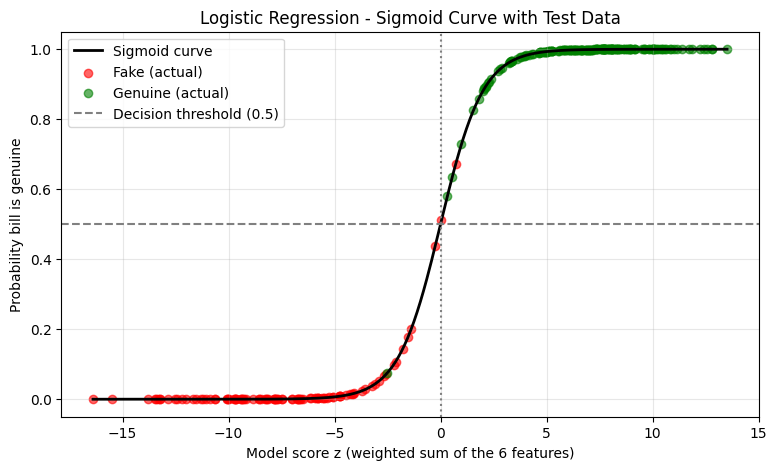

In [37]:
# PART 5: GRAPHS (matplotlib)
# =====================================================
rng = np.random.default_rng(42)
coefs = model.named_steps["logreg"].coef_[0]


# ---- Graph 1: Logistic regression S-curve (sigmoid) ----
# z = w1*x1 + w2*x2 + ... + b  (the model's score for each bill)
z_test = model.decision_function(X_test)
z_line = np.linspace(min(z_test.min(), -8), max(z_test.max(), 8), 400)
sigmoid = 1 / (1 + np.exp(-z_line))            # p = 1 / (1 + e^-z)

plt.figure(figsize=(9, 5))
y_test_arr = y_test.to_numpy()
plt.plot(z_line, sigmoid, color="black", linewidth=2, label="Sigmoid curve")
plt.scatter(z_test[y_test_arr == 0], y_prob[y_test_arr == 0],color="red", alpha=0.6, label="Fake (actual)")
plt.scatter(z_test[y_test_arr == 1], y_prob[y_test_arr == 1],
            color="green", alpha=0.6, label="Genuine (actual)")
plt.axhline(0.5, color="gray", linestyle="--", label="Decision threshold (0.5)")
plt.axvline(0, color="gray", linestyle=":")
plt.xlabel("Model score z (weighted sum of the 6 features)")
plt.ylabel("Probability bill is genuine")
plt.title("Logistic Regression - Sigmoid Curve with Test Data")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("logistic_sigmoid_curve.png", dpi=150, bbox_inches="tight")
plt.show()


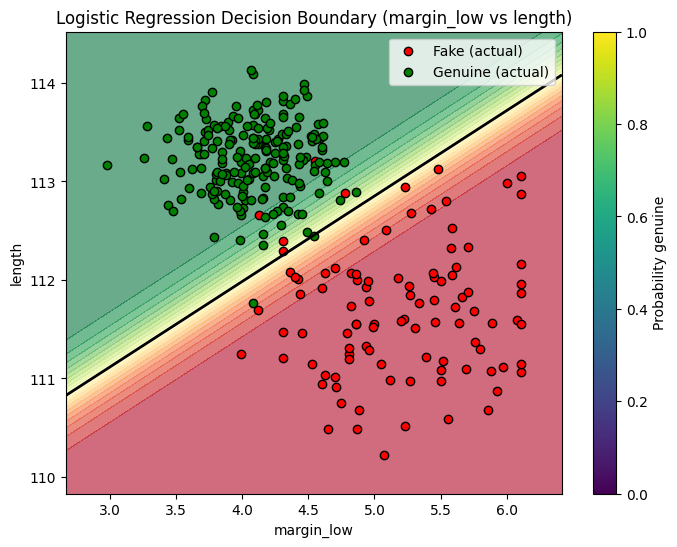

In [38]:

# ---- Graph 2: 2D decision boundary on the 2 strongest features ----
# A separate 2-feature model is fitted only to draw this picture
top2 = np.argsort(np.abs(coefs))[-2:]
f1_name, f2_name = feature_cols[top2[0]], feature_cols[top2[1]]

viz_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42)),
])
viz_model.fit(X_train[[f1_name, f2_name]], y_train)

x_min, x_max = X_test[f1_name].min(), X_test[f1_name].max()
y_min, y_max = X_test[f2_name].min(), X_test[f2_name].max()
x_pad, y_pad = 0.1 * (x_max - x_min), 0.1 * (y_max - y_min)
xx, yy = np.meshgrid(
    np.linspace(x_min - x_pad, x_max + x_pad, 300),
    np.linspace(y_min - y_pad, y_max + y_pad, 300),
)
grid = pd.DataFrame({f1_name: xx.ravel(), f2_name: yy.ravel()})
probs = viz_model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, probs, levels=20, cmap="RdYlGn", alpha=0.6)
plt.contour(xx, yy, probs, levels=[0.5], colors="black", linewidths=2)   # decision boundary
plt.scatter(X_test.loc[y_test == 0, f1_name], X_test.loc[y_test == 0, f2_name],
            color="red", edgecolor="black", label="Fake (actual)")
plt.scatter(X_test.loc[y_test == 1, f1_name], X_test.loc[y_test == 1, f2_name],
            color="green", edgecolor="black", label="Genuine (actual)")
plt.colorbar(label="Probability genuine")
plt.xlabel(f1_name)
plt.ylabel(f2_name)
plt.title(f"Logistic Regression Decision Boundary ({f1_name} vs {f2_name})")
plt.legend()
plt.savefig("decision_boundary.png", dpi=150, bbox_inches="tight")
plt.show()




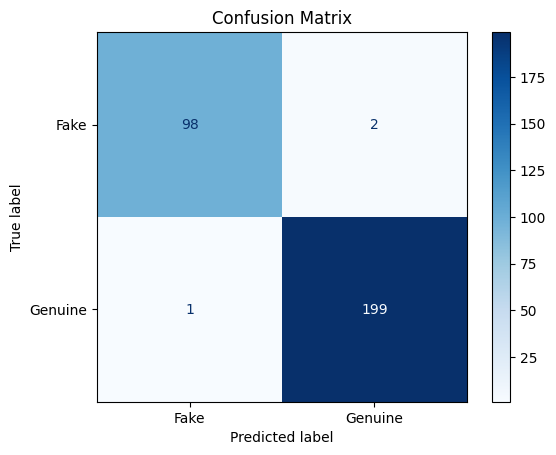

In [ ]:

# ---- Graph 3: Confusion matrix ----
ConfusionMatrixDisplay(cm, display_labels=["Fake", "Genuine"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

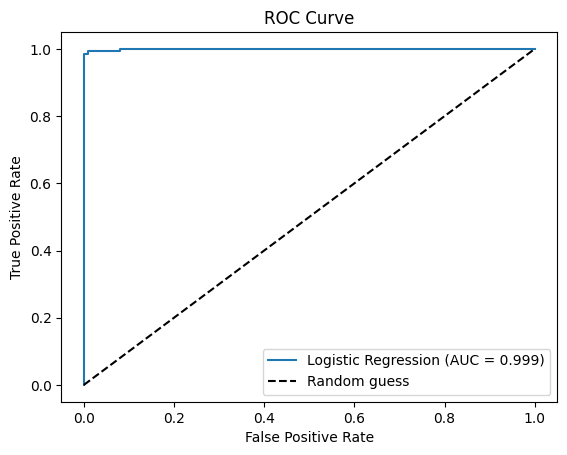


Saved graphs: logistic_sigmoid_curve.png, decision_boundary.png,
feature_coefficients.png, confusion_matrix.png, roc_curve.png


In [ ]:

# ---- Graph 4: ROC curve ----
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure()
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.savefig("roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nSaved graphs: logistic_sigmoid_curve.png, decision_boundary.png,")
print("feature_coefficients.png, confusion_matrix.png, roc_curve.png")

Learning Curve

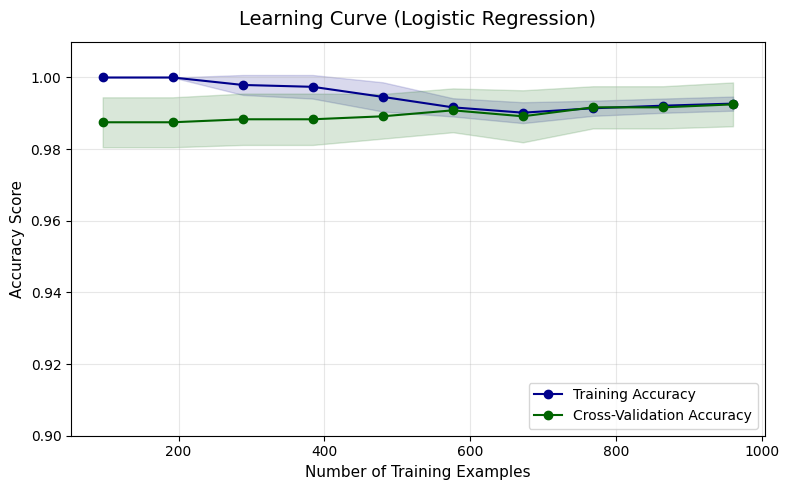

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# 1. Compute training and cross-validation scores across increasing training sizes
train_sizes, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X_train,
    y=y_train,
    cv=5,                                      # 5-fold cross-validation
    train_sizes=np.linspace(0.1, 1.0, 10),     # 10% to 100% of training data
    scoring="accuracy",
    n_jobs=-1
)

# 2. Calculate mean and standard deviation across folds
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

# 3. Plot the Learning Curve
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, "o-", color="darkblue", label="Training Accuracy")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color="darkblue")

plt.plot(train_sizes, val_mean, "o-", color="darkgreen", label="Cross-Validation Accuracy")
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color="darkgreen")

plt.xlabel("Number of Training Examples", fontsize=11)
plt.ylabel("Accuracy Score", fontsize=11)
plt.title("Learning Curve (Logistic Regression)", fontsize=14, pad=12)
plt.ylim([0.90, 1.01])
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("learning_curve.png", dpi=300)
plt.show()


Precision Recall Graph

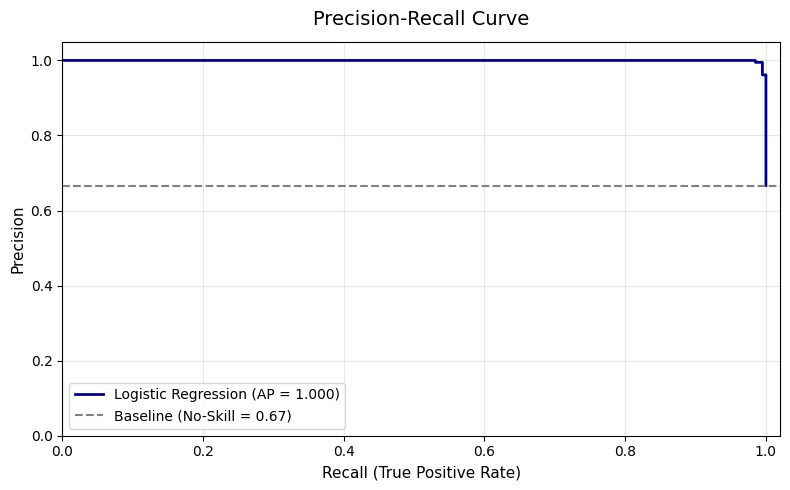

In [47]:

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# 1. Compute precision, recall, and Average Precision (AP) score
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
ap_score = average_precision_score(y_test, y_prob)

# 2. Calculate baseline (proportion of positive/genuine class in y_test)
baseline = y_test.mean()

# 3. Plot the Precision-Recall curve
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, color="darkblue", linewidth=2, label=f"Logistic Regression (AP = {ap_score:.3f})")
plt.axhline(y=baseline, color="gray", linestyle="--", label=f"Baseline (No-Skill = {baseline:.2f})")

plt.xlabel("Recall (True Positive Rate)", fontsize=11)
plt.ylabel("Precision", fontsize=11)
plt.title("Precision-Recall Curve", fontsize=14, pad=12)
plt.xlim([0.0, 1.02])
plt.ylim([0.0, 1.05])
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("precision_recall_curve.png", dpi=300)
plt.show()


Correlation Between Features


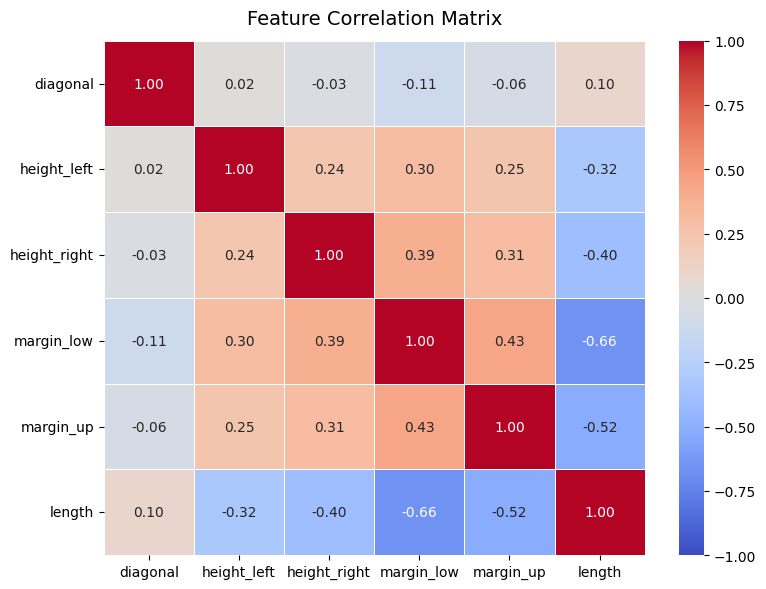

In [48]:
# 1. Compute the correlation matrix for your features
corr_matrix = X.corr()

# 2. Plot the correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,          # Show correlation numbers inside each square
    fmt=".2f",           # Round to 2 decimal places
    cmap="coolwarm",     # Blue for negative, red for positive correlation
    vmin=-1, vmax=1,     # Keep color scale symmetric from -1 to 1
    linewidths=0.5
)

plt.title("Feature Correlation Matrix", fontsize=14, pad=12)
plt.tight_layout()
plt.savefig("feature_correlation.png", dpi=300)
plt.show()